# Лабораторная работа №2. Кластеризация

**Студент:** Александров Артемий Владимирович  
**Вариант:** 5  
**Данные:** `lab2-05.xlsx`

## 1. Загрузка данных

в исходном файле столбцы названы `0` и `1`. Для удобства переименовал в `x` и `y`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans #алгоритм кластеризации
from sklearn.metrics import silhouette_score #функция оценки качества (плотность точек)
from sklearn.model_selection import train_test_split

data = pd.read_excel("lab2-05.xlsx")
data.columns = ["x", "y"]

print(f"Наблюдений: {len(data)}")
data.head(10)

Наблюдений: 1000


,x,y
0,2.139187,0.155126
1,0.400514,-0.958325
2,1.693747,-1.456162
3,1.124378,-7.898880
4,0.323725,-0.774986
5,1.852470,-1.293697
6,1.469658,-1.163515
7,2.717799,-8.752192
8,1.767292,-0.475289
9,1.473603,-0.682888


## 2. Визуализация исходных данных

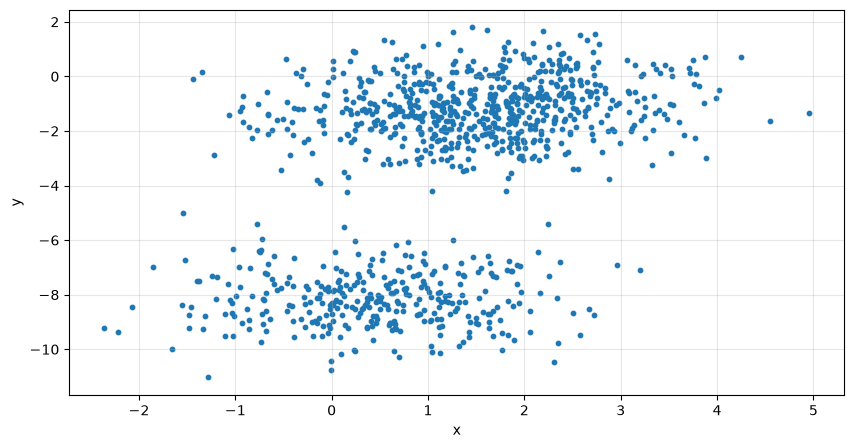

In [20]:
plt.figure(figsize=(10, 5))
plt.scatter(data["x"], data["y"], s=10)
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 3. Оценка числа кластеров

In [ ]:
X = data[["x", "y"]]
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {len(X_train)}")
print(f"Тестовая выборка: {len(X_test)}")

rows = []
for n_clusters in range(2, 9):
    candidate = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_train)
    rows.append({
        "Число кластеров": n_clusters,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(X_train, labels), #чем ближе к 1, тем плотнее точки сидят в своей группе и тем дальше группы друг от друга
    })

comparison = pd.DataFrame(rows)
comparison.round(4)

Обучающая выборка: 800
Тестовая выборка: 200


,Число кластеров,Inertia,Silhouette
0,2,1741.9396,0.7363
1,3,1285.3999,0.4692
2,4,1052.9528,0.4703
3,5,871.8587,0.3389
4,6,755.1102,0.3271
5,7,649.1821,0.3361
6,8,579.4473,0.3301


## 4. Выбор модели

Берётся `KMeans` с `n_clusters=2`. Метод ищет два центра и относит точку к тому центру, который ближе.

## 5. Обучение

In [22]:
model = KMeans(n_clusters=2, n_init=10, random_state=42)
model.fit(X_train)

centers = pd.DataFrame(model.cluster_centers_, columns=["x", "y"])
centers.index = [f"Кластер {i + 1}" for i in range(len(centers))]

print("Центры кластеров:")
centers.round(4)

Центры кластеров:


,x,y
Кластер 1,1.5079,-1.1720
Кластер 2,0.4959,-8.1852


## 6. Проверка качества

In [23]:
train_labels = model.labels_
test_labels = model.predict(X_test)

quality = pd.DataFrame(
    [
        {
            "Выборка": "Обучающая",
            "Точек": len(X_train),
            "Silhouette": silhouette_score(X_train, train_labels),
        },
        {
            "Выборка": "Тестовая",
            "Точек": len(X_test),
            "Silhouette": silhouette_score(X_test, test_labels),
        },
    ]
)
quality.round(4)

,Выборка,Точек,Silhouette
0,Обучающая,800,0.7363
1,Тестовая,200,0.7402


## 7. Визуализация результата

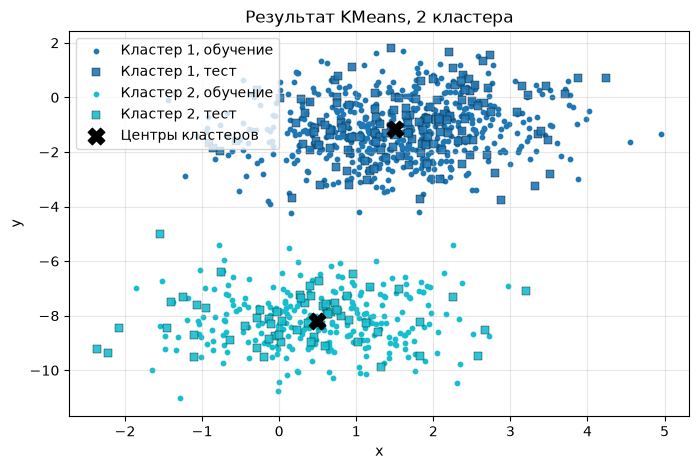

In [24]:
cluster_colors = ["#1f77b4", "#17becf"]
train_xy = X_train.to_numpy()
test_xy = X_test.to_numpy()

plt.figure(figsize=(8, 5))
for cluster, color in enumerate(cluster_colors):
    train_part = train_xy[train_labels == cluster]
    test_part = test_xy[test_labels == cluster]
    plt.scatter(
        train_part[:, 0],
        train_part[:, 1],
        s=10,
        color=color,
        label=f"Кластер {cluster + 1}, обучение",
    )
    plt.scatter(
        test_part[:, 0],
        test_part[:, 1],
        s=32,
        marker="s",
        alpha=0.9,
        color=color,
        edgecolors="black",
        linewidths=0.3,
        label=f"Кластер {cluster + 1}, тест",
    )

plt.scatter(
    centers["x"],
    centers["y"],
    c="black",
    marker="X",
    s=140,
    zorder=5,
    label="Центры кластеров",
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Результат KMeans, 2 кластера")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

## Вывод

В данных два кластера. Большая группа собрана вокруг центра (1.51, −1.17), меньшая - вокруг (0.50, −8.19). На обучении в них попало 528 и 272 точки, на тесте 139 и 61 соответственно.
KMeans с двумя кластерами обучен на 800 точках. Silhouette на обучении равен 0,74, на тестовых 200 точках тоже 0,74. 